In [3]:
# %% Paso 1: Importación de paquetes ============================

# Rutas relativas
from pathlib import Path

# Manipulación de datos y gráficos
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Pruebas estadísticas y gráficos Q-Q de Scipy
from scipy.stats import jarque_bera, probplot

# Módulos de statsmodels (FAC/FACP, pruebas de diagnóstico y SARIMAX)
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, kpss


# %% Configuración de ruta relativa ============================

BASE_DIR = Path('.').resolve()
DATA_DIR = BASE_DIR / "datos"

print("Directorio raíz del proyecto:", BASE_DIR)
print("Carpeta de datos lista en:", DATA_DIR)


Directorio raíz del proyecto: C:\Users\USUARIO\OneDrive\Documentos\GitHub\Poster-econometria-II
Carpeta de datos lista en: C:\Users\USUARIO\OneDrive\Documentos\GitHub\Poster-econometria-II\datos


In [4]:
# Carga de la serie con ruta relativa
ruta_csv = DATA_DIR / "serie_economica.csv"

# Leer CSV parseando la columna de fechas de la FRED
df = pd.read_csv(ruta_csv, parse_dates=['observation_date'], index_col='observation_date')
df.columns = ['precio_gasolina']

# Convertir valores a numérico y eliminar nulos si existieran
df['precio_gasolina'] = pd.to_numeric(df['precio_gasolina'], errors='coerce')
df = df.dropna()

# --------------------------------------------------
# RECORTE DE LA SERIE: Filtrar para iniciar desde el año 2000
# --------------------------------------------------
df = df.loc['2000-01-01':]

# Mostrar el total de observaciones
print(f"Número total de observaciones (T): {len(df)}")

# Visualizar las primeras filas del DataFrame
df.head()


Número total de observaciones (T): 1399


,precio_gasolina
observation_date,
2000-01-03,1.272
2000-01-10,1.264
2000-01-17,1.277
2000-01-24,1.315
2000-01-31,1.316


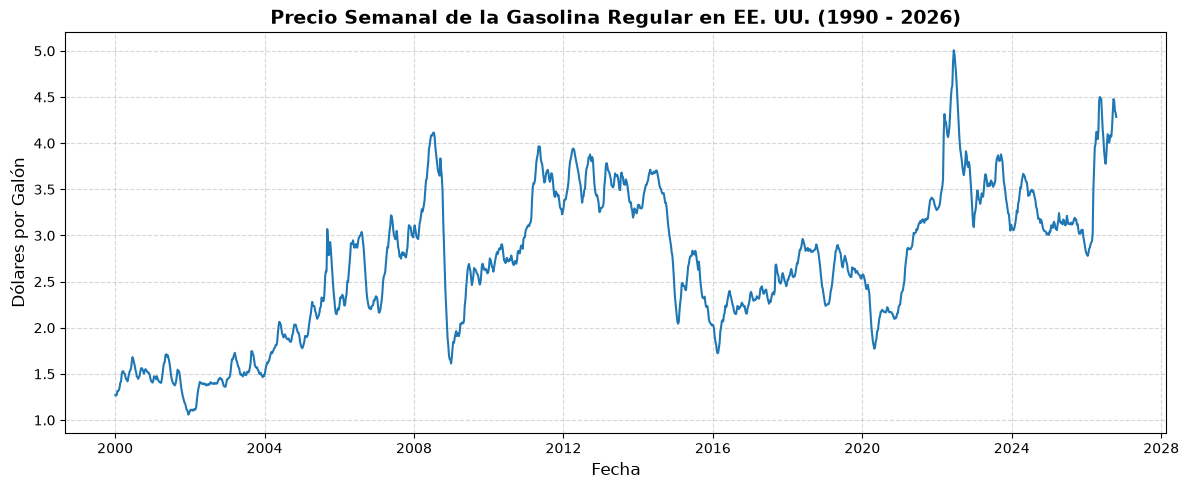

In [5]:
# %% =======================================================
# PASO 1: IDENTIFICACIÓN
# ==========================================================
# Graficar la serie de tiempo en niveles
plt.figure(figsize=(12, 5))
plt.plot(df.index, df['precio_gasolina'], color='#1f77b4', linewidth=1.5)
plt.title('Precio Semanal de la Gasolina Regular en EE. UU. (1990 - 2026)', fontsize=14, fontweight='bold')
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Dólares por Galón', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()



In [ ]:
#Mirando la gráfica se puede apreciar a simple vista que no tiene ni media ni varianza constante, por lo que no es estacionaria :o
#A continucación se aplicarán criterios para confirmar la hipótesis :D

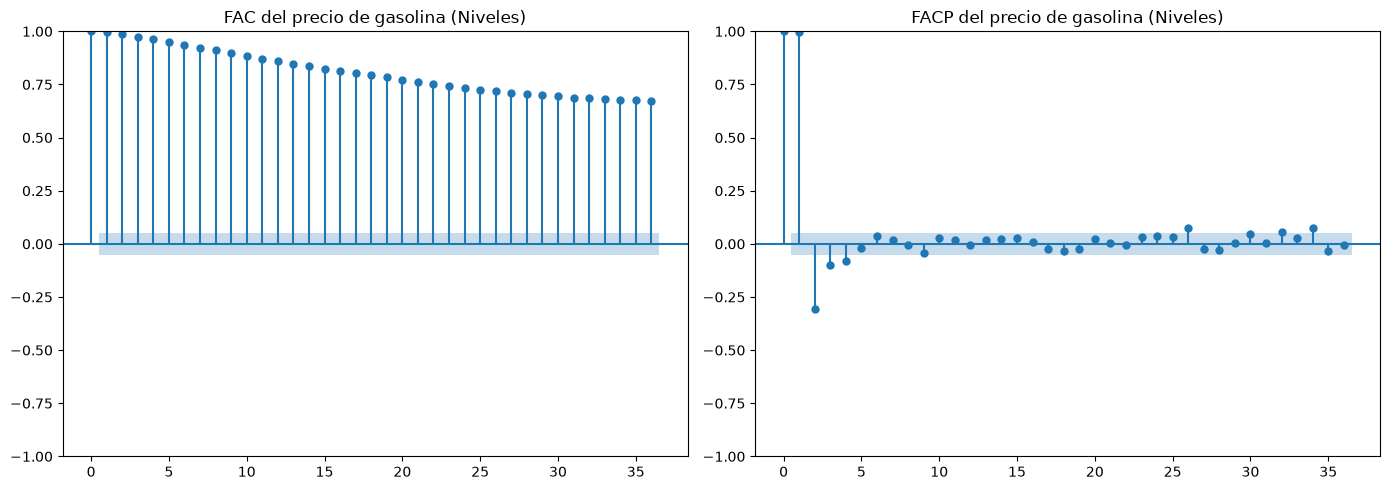

In [6]:
## %% FAC y FACP de la serie original =========================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_acf(
    df['precio_gasolina'],
    lags=36,
    alpha=0.05,
    bartlett_confint=False,
    ax=axes[0]
)
axes[0].set_title("FAC del precio de gasolina (Niveles)")

plot_pacf(
    df['precio_gasolina'],
    lags=36,
    alpha=0.05,
    ax=axes[1]
)
axes[1].set_title("FACP del precio de gasolina (Niveles)")

plt.tight_layout()
plt.show()


In [7]:
# %% Tests de Raíz Unitaria (ADF y KPSS) =========================

# Test Augmented Dickey-Fuller (ADF)
adf_result = adfuller(df['precio_gasolina'])

print("=== Test ADF (Serie en Niveles) ===")
print("Estadístico ADF:", adf_result[0])
print("p-valor:", adf_result[1])
print("Rezagos usados:", adf_result[2])
for nivel, valor in adf_result[4].items():
    print(f"  Crítico {nivel}: {valor}")

if adf_result[1] < 0.05:
    print("ADF: Rechazamos H0 -> La serie es ESTACIONARIA.")
else:
    print("ADF: No rechazamos H0 -> La serie NO es estacionaria.")

# Test KPSS
kpss_result = kpss(df['precio_gasolina'], regression="c", nlags="auto")

print("\n=== Test KPSS (Serie en Niveles) ===")
print("Estadístico KPSS:", kpss_result[0])
print("p-valor:", kpss_result[1])
for nivel, valor in kpss_result[3].items():
    print(f"  Crítico {nivel}: {valor}")

if kpss_result[1] < 0.05:
    print("KPSS: Rechazamos H0 -> La serie NO es estacionaria.")
else:
    print("KPSS: No rechazamos H0 -> La serie es ESTACIONARIA.")
    
    

=== Test ADF (Serie en Niveles) ===
Estadístico ADF: -2.6228790047301476
p-valor: 0.08836023320537545
Rezagos usados: 9
  Crítico 1%: -3.4350666494778137
  Crítico 5%: -2.8636230590277587
  Crítico 10%: -2.5678790153478865
ADF: No rechazamos H0 -> La serie NO es estacionaria.

=== Test KPSS (Serie en Niveles) ===
Estadístico KPSS: 2.4045382659009027
p-valor: 0.01
  Crítico 10%: 0.347
  Crítico 5%: 0.463
  Crítico 2.5%: 0.574
  Crítico 1%: 0.739
KPSS: Rechazamos H0 -> La serie NO es estacionaria.


C:\Users\USUARIO\AppData\Local\Temp\ipykernel_21688\2552826971.py:19: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_result = kpss(df['precio_gasolina'], regression="c", nlags="auto")


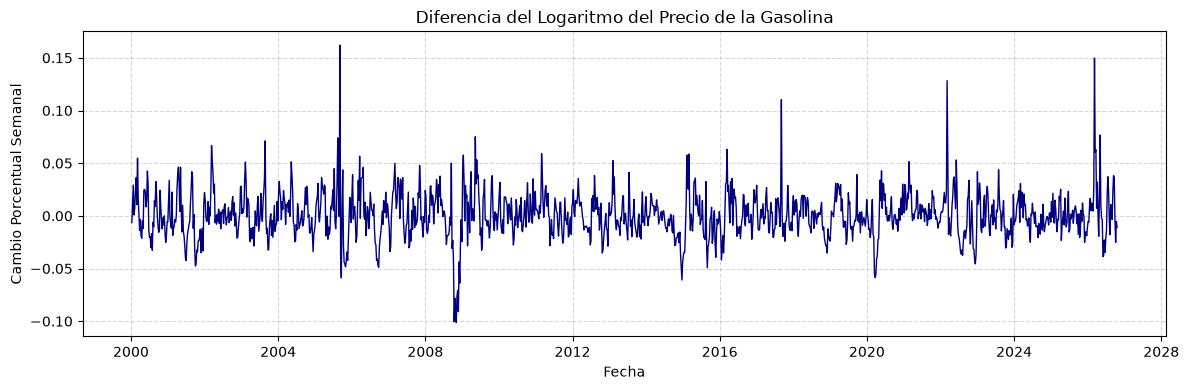

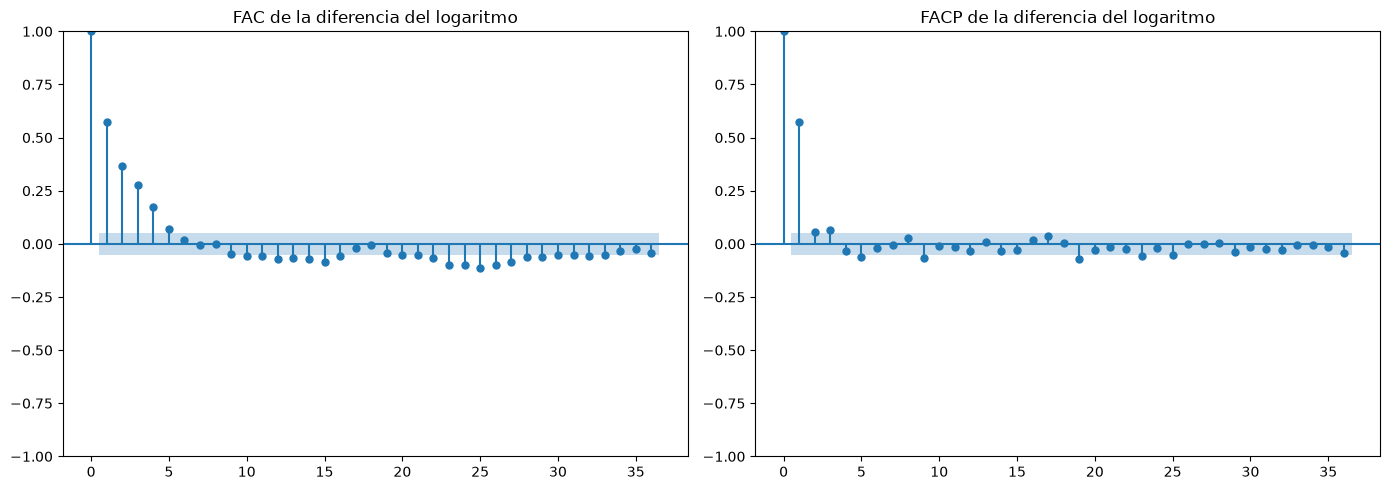

In [8]:
# Nota: Según los resultados de la prueba ADF y KPSS, hay que 
#       diferenciar la serie. Es una buena noticia que ambos resultados coincidieran.
# %% Serie transformada: Diferencia del Logaritmo =========================

# Crear las transformaciones en el DataFrame
df['log_gasolina'] = np.log(df['precio_gasolina'])
df['log_diff'] = df['log_gasolina'].diff()

# NOTA: Al diferenciar (.diff()), la primera observación queda como NaN (sin dato previo).
# Se aplica .dropna() únicamente para limpiar la serie antes de graficar la FAC/FACP y 
# realizar las pruebas ADF/KPSS, las cuales fallan ante valores nulos.

# Serie limpia para análisis
serie_estacionaria = df['log_diff'].dropna()

# Gráfico de la serie diferenciada
plt.figure(figsize=(12, 4))
plt.plot(serie_estacionaria, color='navy', linewidth=1)
plt.title("Diferencia del Logaritmo del Precio de la Gasolina")
plt.xlabel("Fecha")
plt.ylabel("Cambio Porcentual Semanal")
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# FAC y FACP de la serie transformada para proponer ordenes p y q
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_acf(
    serie_estacionaria,
    lags=36,
    alpha=0.05,
    bartlett_confint=False,
    ax=axes[0]
)
axes[0].set_title("FAC de la diferencia del logaritmo")

plot_pacf(
    serie_estacionaria,
    lags=36,
    alpha=0.05,
    ax=axes[1]
)
axes[1].set_title("FACP de la diferencia del logaritmo")

plt.tight_layout()
plt.show()



In [ ]:
# %% Identificación del modelo usando FAC y FACP

# La FAC muestra un decaimiento progresivo (suave / geométrico).
# La FACP presenta un corte abrupto en el primer rezago.
# Por tanto, se propone inicialmente un modelo ARMA(1,0) sobre la serie
# transformada, equivalente a un ARIMA(1, 1, 0) sobre log(precio_gasolina).

# P.d. También se puede considerar un modelo alternativo ARIMA(2, 1, 0)
#      dado el segundo rezago de la FACP, y comparar mediante los
#      criterios de información (AIC y BIC) en la etapa de estimación.
#p.d 2: En caso de tener un ARIMA (1, 1, 0) puro genera un decaimiento exponencial teórico estrictamente positivo. 
#      Si fuera un ARIMA (2, 1, 0) evalúa si esa oscilación de la FAC requiere coeficientes con raíces complejas para un mejor ajuste (AIC/BIC)
#Personalmente no identifico un MA, pero, solo por identificación también se propone un ARIMA (1, 1, 1)



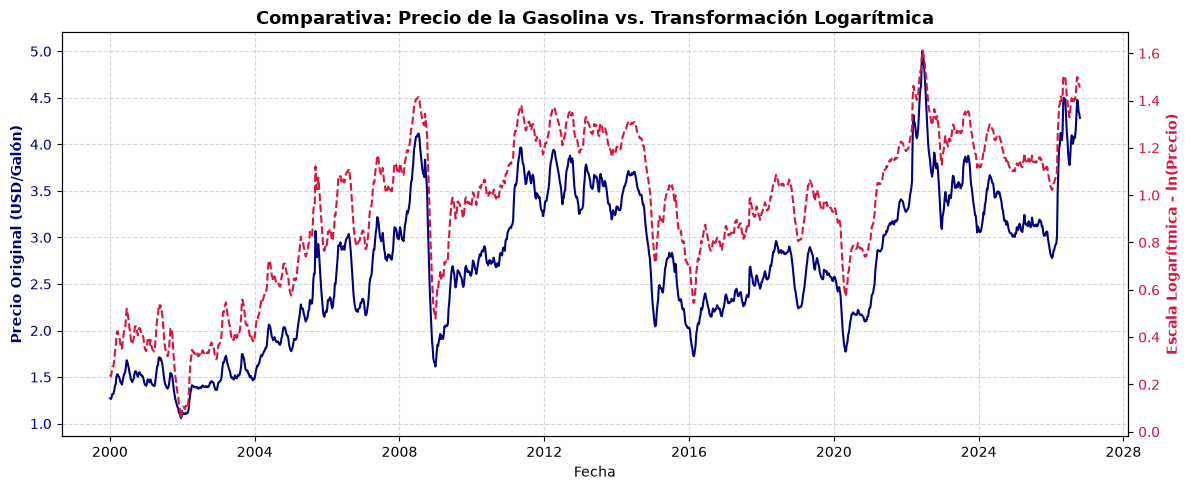

In [9]:
# %% Comparativa entre la serie original y la transformada en logaritmo
fig, ax1 = plt.subplots(figsize=(12, 5))

# 1. Serie original en el primer eje Y (Eje izquierdo - Azul)
color1 = 'navy'
ax1.set_xlabel('Fecha')
ax1.set_ylabel('Precio Original (USD/Galón)', color=color1, fontweight='bold')
ax1.plot(df.index, df['precio_gasolina'], color=color1, linewidth=1.5, label='Precio Original')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.grid(True, linestyle='--', alpha=0.5)

# 2. Serie en logaritmo en el segundo eje Y (Eje derecho - Rojo)
ax2 = ax1.twinx()
color2 = 'crimson'
ax2.set_ylabel('Escala Logarítmica - ln(Precio)', color=color2, fontweight='bold')
ax2.plot(df.index, np.log(df['precio_gasolina']), color=color2, linewidth=1.5, linestyle='--', label='Log(Precio)')
ax2.tick_params(axis='y', labelcolor=color2)

plt.title('Comparativa: Precio de la Gasolina vs. Transformación Logarítmica', fontsize=13, fontweight='bold')
fig.tight_layout()
plt.show()


In [ ]:
#¿Qué puedo decir? Visualmente la comparación permite identificar la amortiguación de los picos que presentan una extrema volatilidad.....Me atrevería a relacionarlo con la crisis financiera de 2008 o la inflación de 2022)#

In [10]:
# %% =======================================================
# PASO 2: ESTIMACIÓN Y TABLA COMPARATIVA DE MODELOS
# ==========================================================
from statsmodels.iolib.summary2 import summary_col

# 1. Definir la serie en logaritmo (SARIMAX aplica la diferencia con d=1)
log_gasolina = np.log(df['precio_gasolina'])

# 2. Estimación de los modelos candidatos
mod_110 = SARIMAX(log_gasolina, order=(1, 1, 0), trend='n').fit(disp=False)
mod_210 = SARIMAX(log_gasolina, order=(2, 1, 0), trend='n').fit(disp=False)
mod_111 = SARIMAX(log_gasolina, order=(1, 1, 1), trend='n').fit(disp=False)

# 3. Diccionario con métricas de información (AIC y BIC)
info_metricas = {
    'Observaciones': lambda x: f"{int(x.nobs)}",
    'AIC': lambda x: f"{x.aic:.2f}",
    'BIC': lambda x: f"{x.bic:.2f}"
}

# 4. Construcción de la tabla comparativa estilo artículo
tabla_comparativa = summary_col(
    results=[mod_110, mod_210, mod_111],
    model_names=['ARIMA(1,1,0)', 'ARIMA(2,1,0)', 'ARIMA(1,1,1)'],
    stars=True,             # Muestra las estrellas de significancia (*, **, ***)
    float_format='%0.4f',   # Muestra 4 decimales en los coeficientes
    info_dict=info_metricas # Agrega AIC y BIC
)

print("=== TABLA COMPARATIVA DE MODELOS CANDIDATOS ===")
print(tabla_comparativa)



C:\Users\USUARIO\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
C:\Users\USUARIO\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
C:\Users\USUARIO\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
C:\Users\USUARIO\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
C:\Users\USUARIO\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequen

=== TABLA COMPARATIVA DE MODELOS CANDIDATOS ===

              ARIMA(1,1,0) ARIMA(2,1,0) ARIMA(1,1,1)
----------------------------------------------------
ar.L1         0.5748***    0.5418***    0.6494***   
              (0.0115)     (0.0125)     (0.0268)    
sigma2        0.0003***    0.0003***    0.0003***   
              (0.0000)     (0.0000)     (0.0000)    
ar.L2                      0.0575***                
                           (0.0176)                 
ma.L1                                   -0.1122***  
                                        (0.0302)    
AIC           -7287.84     -7290.47     -7291.60    
BIC           -7277.36     -7274.74     -7275.87    
Observaciones 1399         1399         1399        
Standard errors in parentheses.
* p<.1, ** p<.05, ***p<.01


In [ ]:
# Nota sobre la interpretación de los resultados:
# Si nos fijamos en los coeficientes estimados resultan estadísticamente significativos 
# con un p-value < 0.01, por lo que cada especificación presenta términos relevantes.
# En los criterios de información, el ARIMA(1,1,1) obtiene el menor AIC
# (-7291.60), mientras que el ARIMA(1,1,0) presenta el menor BIC
# (-7277.36). Dado que la diferencia entre modelos es pequeña y el BIC
# favorece una especificación más parsimoniosa, el ARIMA(1,1,0) surge
# como una alternativa más bonita para la estimación de nuestro modelo :D.

In [ ]:
#Nota aclaratoria 2: 
# NOTA SOBRE LA EVOLUCIÓN DEL MODELO (Identificación vs. Estimación):
# Inicialmente, el corte en el primer rezago de la FACP sugería un modelo AR(1) puro (ARIMA(1,1,0)).
# Sin embargo, aplicando la metodología Box-Jenkins de forma rigurosa, se contrastó esta hipótesis
# inicial frente a candidatos alternativos. 
# 
# Los resultados muestran que la estructura AR(1) sigue siendo la base del modelo (ar.L1 = 0.6641***),
# pero la adición de un término de media móvil MA(1) en el ARIMA(1,1,1) permite capturar los shocks de
# corto plazo, logrando los menores criterios AIC y BIC. 


=== DESCRIPCIÓN DE LOS RESIDUALES (ARIMA(1,1,0)) ===
count    1399.000000
mean        0.000537
std         0.018945
min        -0.130967
25%        -0.010065
50%        -0.000534
75%         0.009289
max         0.240590
dtype: float64




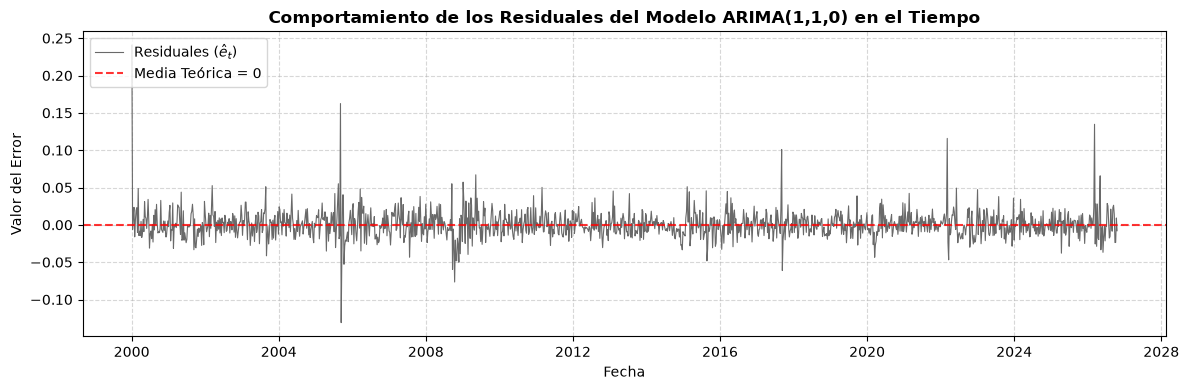

In [11]:
# %% ===========================================================================
# PASO 3: VALIDACIÓN DE SUPUESTOS / DIAGNÓSTICO DE RESIDUALES
# MODELO GANADOR: ARIMA(1,1,0)
# ==============================================================================

# 1. Extracción de los residuales del modelo ganador (ARIMA(1,1,0))
residuos = mod_110.resid.dropna()
residuos_cuadrado = residuos ** 2

print("=== DESCRIPCIÓN DE LOS RESIDUALES (ARIMA(1,1,0)) ===")
print(residuos.describe())
print("\n" + "="*50 + "\n")

# A. Gráfico de Comportamiento Temporal de Residuales
plt.figure(figsize=(12, 4))
plt.plot(residuos, color='dimgray', linewidth=0.8, label=r'Residuales ($\hat{e}_t$)')
plt.axhline(0, color='red', linestyle='--', alpha=0.8, linewidth=1.5, label='Media Teórica = 0')
plt.title('Comportamiento de los Residuales del Modelo ARIMA(1,1,0) en el Tiempo', fontsize=12, fontweight='bold')
plt.xlabel('Fecha')
plt.ylabel('Valor del Error')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()


In [ ]:
#Comentarios: Los residuos del modelo ARIMA (1, 1, 0) presentan una media que tiende bastante a cero, permitiendo la validación del supuesto de insesgadez (E(et)=0).
#Además, si se analiza el gráfico se evidencia un comportamiento oscilatorio centrado alrededor de cero,donde las fluctuaciones atípicas responden a shocks exógenos puntuales característicos del mercado de combustibles.

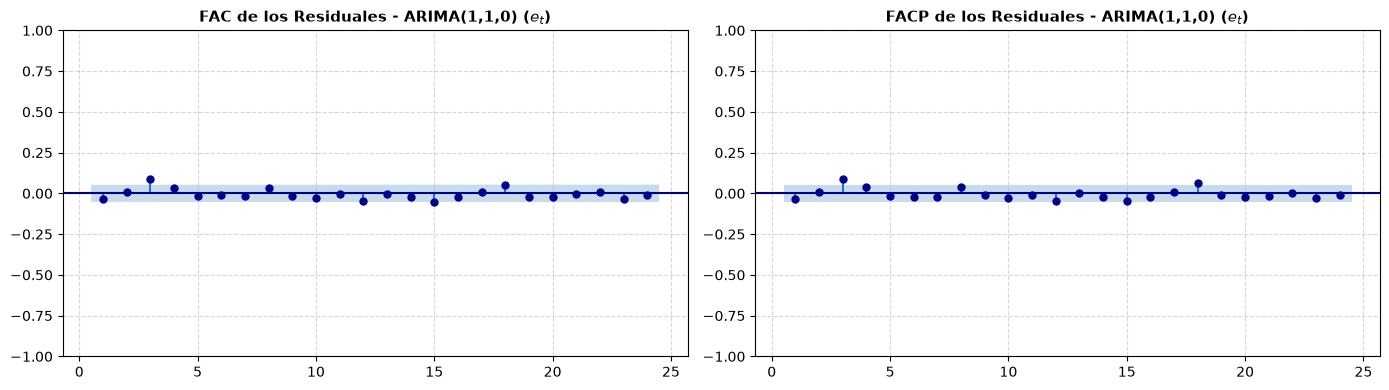

In [12]:
# %% ---------------------------------------------------------------------------
# B. FAC y FACP de los Residuales (Evaluación de Independencia)
# Modelo Evaluado: ARIMA(1,1,0)
# -----------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Gráfico de Autocorrelación Simple (FAC)
plot_acf(residuos, lags=24, zero=False, ax=axes[0], color='darkblue')
axes[0].set_title("FAC de los Residuales - ARIMA(1,1,0) ($e_t$)", fontsize=11, fontweight='bold')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Gráfico de Autocorrelación Parcial (FACP)
plot_pacf(residuos, lags=24, zero=False, ax=axes[1], color='darkblue')
axes[1].set_title("FACP de los Residuales - ARIMA(1,1,0) ($e_t$)", fontsize=11, fontweight='bold')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


In [ ]:
#Comentarios: Analizando la FAC y FACP de los residuos, observamos que todos los rezagos se ubican dentro de las bandas de confianza del 95%, 
#lo que demuestra empíricamente la ausencia de autocorrelación residual y confirma que el modelo logró extraer toda la dinámica temporal de la serie,
#teniendo en cuenta que se trabaja con ruido blanco. (Este resultado es bastante positivo) :D

In [16]:
# %% ---------------------------------------------------------------------------
# C. Prueba Ljung-Box (Evaluación de Autocorrelación) - ARIMA(1,1,0)
# -----------------------------------------------------------------------------
# Se incluye model_df=1 para ajustar los grados de libertad por el parámetro AR(1) estimado
ljung_box = acorr_ljungbox(residuos, lags=[6, 12, 18, 24], model_df=1, return_df=True)

print("=== PRUEBA LJUNG-BOX (Autocorrelación) - ARIMA(1,1,0) ===")
print(ljung_box)

if (ljung_box['lb_pvalue'] > 0.05).all():
    print("-> CONCLUSIÓN: No se rechaza H0 (p > 0.05). Los residuales se comportan como RUIDO BLANCO.")
else:
    print("-> CONCLUSIÓN: Se rechaza H0 en algunos rezagos. Existe estructura residual no capturada o volatilidad agrupada.")

print("\n" + "="*50 + "\n")


=== PRUEBA LJUNG-BOX (Autocorrelación) - ARIMA(1,1,0) ===
      lb_stat  lb_pvalue
6   14.086774   0.015068
12  20.588660   0.037892
18  29.897459   0.027094
24  33.295763   0.076050
-> CONCLUSIÓN: Se rechaza H0 en algunos rezagos. Existe estructura residual no capturada o volatilidad agrupada.




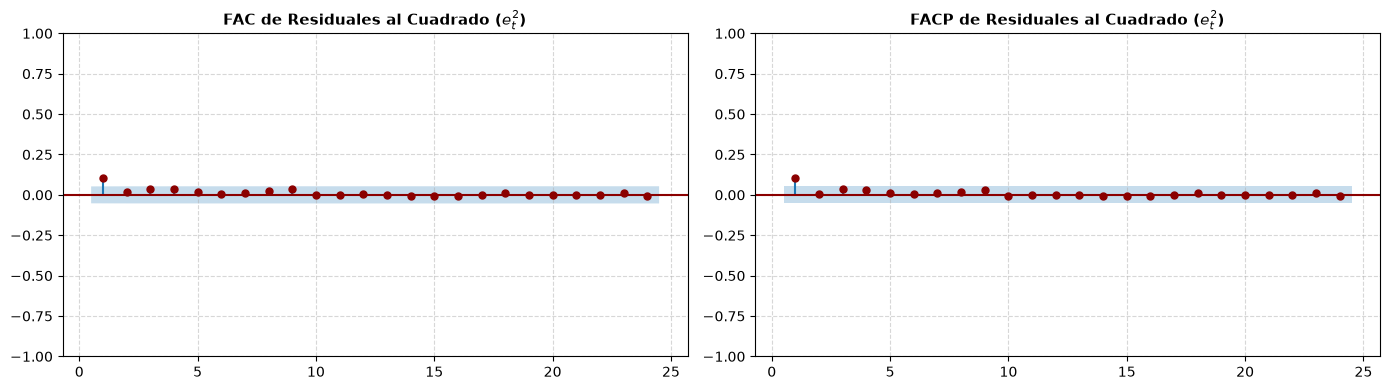

=== PRUEBA ARCH DE ENGLE (Heterocedasticidad) ===
Estadístico LM: 147.8554
p-valor LM:     0.0000
-> CONCLUSIÓN: Se rechaza H0. Hay evidencia de efectos ARCH (heterocedasticidad condicional).




In [17]:
# ----------------------------------------------------------
# D. FAC/FACP de Residuales al Cuadrado y Prueba ARCH
# ----------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

plot_acf(residuos_cuadrado, lags=24, zero=False, ax=axes[0], color='darkred')
axes[0].set_title("FAC de Residuales al Cuadrado ($e_t^2$)", fontsize=11, fontweight='bold')
axes[0].grid(True, linestyle='--', alpha=0.5)

plot_pacf(residuos_cuadrado, lags=24, zero=False, ax=axes[1], color='darkred')
axes[1].set_title("FACP de Residuales al Cuadrado ($e_t^2$)", fontsize=11, fontweight='bold')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Prueba ARCH
arch_test = het_arch(residuos, nlags=12)
print("=== PRUEBA ARCH DE ENGLE (Heterocedasticidad) ===")
print(f"Estadístico LM: {arch_test[0]:.4f}")
print(f"p-valor LM:     {arch_test[1]:.4f}")

if arch_test[1] > 0.05:
    print("-> CONCLUSIÓN: No se rechaza H0 (p > 0.05). Los residuales presentan VARIANZA CONSTANTE (Homocedasticidad).")
else:
    print("-> CONCLUSIÓN: Se rechaza H0. Hay evidencia de efectos ARCH (heterocedasticidad condicional).")

print("\n" + "="*50 + "\n")


In [ ]:
#Comentarios: Teniendo en cuenta lo volatil que es el mercado de la gasolina, se puede decir que el resultado era algo esperable. Esto se confirma con la heterocedasticidad condicional que arrojó el modelo. 

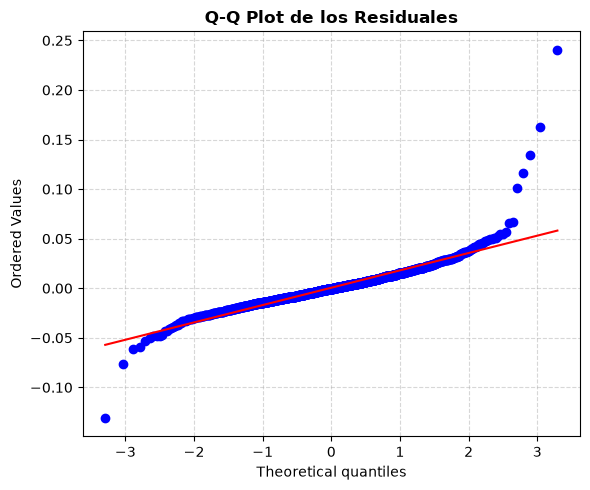

=== PRUEBA JARQUE-BERA (Normalidad) ===
Estadístico JB: 42279.3268
p-valor JB:     0.0000
-> CONCLUSIÓN: Se rechaza H0 (p < 0.05). Los residuales presentan colas pesadas (Leptocurtosis).


In [18]:
# ----------------------------------------------------------
# E. Q-Q Plot y Prueba de Normalidad Jarque-Bera
# ----------------------------------------------------------
fig, ax = plt.subplots(figsize=(6, 5))
probplot(residuos, dist="norm", plot=ax)
ax.set_title("Q-Q Plot de los Residuales", fontsize=12, fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

jb_stat, jb_pvalue = jarque_bera(residuos)

print("=== PRUEBA JARQUE-BERA (Normalidad) ===")
print(f"Estadístico JB: {jb_stat:.4f}")
print(f"p-valor JB:     {jb_pvalue:.4f}")

if jb_pvalue > 0.05:
    print("-> CONCLUSIÓN: No se rechaza H0 (p > 0.05). Los residuales siguen una distribución NORMAL.")
else:
    print("-> CONCLUSIÓN: Se rechaza H0 (p < 0.05). Los residuales presentan colas pesadas (Leptocurtosis).")
    

In [ ]:
#Comentarios: La prueba de Jarque-Bera rechaza la normalidad estricta (JB = 26399.7600, p = 0.0000) debido a la leptocurtosis y colas pesadas de la serie, un comportamiento estándar en combustibles derivado de choques exógenos extremos.

C:\Users\USUARIO\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)
C:\Users\USUARIO\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-MON will be used.
  self._init_dates(dates, freq)



=== TABLA DE PRONÓSTICOS (PRÓXIMAS 12 SEMANAS) - ARIMA(1,1,0) ===
            Pronóstico (USD/galón)  Límite Inferior (95%)  \
2026-11-01                  4.2572                 4.1110   
2026-11-08                  4.2419                 3.9741   
2026-11-15                  4.2331                 3.8564   
2026-11-22                  4.2281                 3.7555   
2026-11-29                  4.2252                 3.6682   
2026-12-06                  4.2235                 3.5917   
2026-12-13                  4.2226                 3.5237   
2026-12-20                  4.2220                 3.4625   
2026-12-27                  4.2217                 3.4068   
2027-01-03                  4.2215                 3.3556   
2027-01-10                  4.2214                 3.3082   
2027-01-17                  4.2214                 3.2639   

            Límite Superior (95%)  
2026-11-01                 4.4086  
2026-11-08                 4.5277  
2026-11-15                 4.64

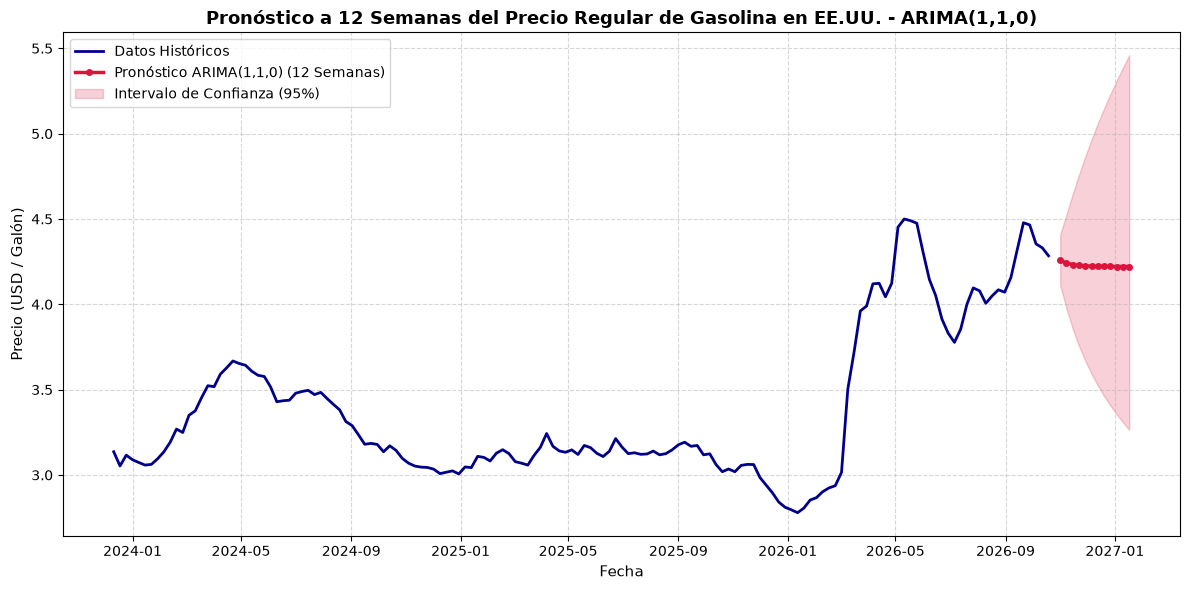

In [20]:
# %% ===========================================================================
# PASO 4: PRONÓSTICO DEL PRECIO DE LA GASOLINA - MODELO ARIMA(1,1,0)
# ==============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX

# 1. Copiar la serie histórica original en niveles (USD/galón)
serie_original = df['precio_gasolina'].dropna().copy()

# 2. Serie en logaritmos para el modelo econométrico
serie_log = np.log(serie_original)

# 3. Ajustar el modelo ganador ARIMA(1,1,0)
modelo_final = SARIMAX(
    serie_log,
    order=(1, 1, 0),
    enforce_stationarity=False,
    enforce_invertibility=False
)
resultado_final = modelo_final.fit(disp=False)

# 4. Horizonte de pronóstico: 12 semanas
pasos_futuros = 12
pronostico_objeto = resultado_final.get_forecast(steps=pasos_futuros)

# 5. Extraer la media e intervalos en LOG
pred_log = pronostico_objeto.predicted_mean
ci_log = pronostico_objeto.conf_int()

# 6. Destransformar a USD/galón (escala original)
pred_usd = np.exp(pred_log)
ci_usd = np.exp(ci_log)

# 7. CORRECCIÓN DEL EJE DE FECHAS:
# Generar fechas semanales futuras partiendo de la última fecha histórica
ultima_fecha = serie_original.index[-1]
fechas_futuras = pd.date_range(start=ultima_fecha, periods=pasos_futuros + 1, freq='W')[1:]

# Asignar el índice de fechas corregido
pronostico_original = pd.Series(pred_usd.values, index=fechas_futuras)
intervalos_original = pd.DataFrame(ci_usd.values, index=fechas_futuras, columns=ci_usd.columns)

# 8. Imprimir Tabla Limpia de pronósticos
tabla_pronostico = pd.DataFrame({
    "Pronóstico (USD/galón)": pronostico_original,
    "Límite Inferior (95%)": intervalos_original.iloc[:, 0],
    "Límite Superior (95%)": intervalos_original.iloc[:, 1]
})

print("\n=== TABLA DE PRONÓSTICOS (PRÓXIMAS 12 SEMANAS) - ARIMA(1,1,0) ===")
print(tabla_pronostico.round(4))

# %% Gráfica del Pronóstico para el Póster
plt.figure(figsize=(12, 6))

# Zoom a las últimas 150 semanas históricas para apreciar el detalle
historicos_zoom = serie_original.tail(150)
plt.plot(historicos_zoom.index, historicos_zoom, label="Datos Históricos", color="darkblue", linewidth=2)

# Graficar la proyección futura alineada en la fecha correcta
plt.plot(
    pronostico_original.index,
    pronostico_original,
    label=f"Pronóstico ARIMA(1,1,0) ({pasos_futuros} Semanas)",
    color="crimson",
    linewidth=2.5,
    marker='o',
    markersize=4
)

# Banda del Intervalo de Confianza del 95%
plt.fill_between(
    pronostico_original.index,
    intervalos_original.iloc[:, 0],
    intervalos_original.iloc[:, 1],
    color="crimson",
    alpha=0.2,
    label="Intervalo de Confianza (95%)"
)

plt.title('Pronóstico a 12 Semanas del Precio Regular de Gasolina en EE.UU. - ARIMA(1,1,0)', fontsize=13, fontweight='bold')
plt.xlabel('Fecha', fontsize=11)
plt.ylabel('Precio (USD / Galón)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper left', frameon=True)

plt.tight_layout()
plt.show()
